# Pré-études pour Traversées piétonnes : fiabilité OSM (GG) vs vérité terrain GE

**Vérité terrain GE** construite à partir de deux couches OTC :
1. `OTC_MARQUAGE_LIGNE`, `type = "Piéton"` : les contours des bandes jaunes. Les bandes sont filtrées par leur forme, regroupées en traversées, et chaque traversée devient un rectangle plein (rectangle minimal orienté).
2. `OTC_SL_EQUIPEMENT_BOITEFEUX` : si une boîte à feux est à moins de `FEUX_BUFFER` m d'un rectangle, la traversée est classée **avec feux**, sinon **sans feux**.

**Évaluation OSM** (`walk_crossing_nodes`) :
- *Sans feux* : `crossing` ∈ {`marked`, `uncontrolled`, vide} comparé aux rectangles sans feux.
- *Avec feux* : `crossing = traffic_signals` comparé aux rectangles avec feux, puis reprise de la comparaison points de 2_1 (boîtes à feux fusionnées).

Règle d'attribution : chaque nœud OSM est rattaché au rectangle le plus proche dans un rayon `ASSIGN_RADIUS` (distance 0 s'il est dedans). Il est bon si ce rectangle est de la bonne classe.

⚠️ Vocabulaire : dans OSM, `supervised=yes` veut dire *surveillé par un agent* (patrouilleur scolaire), pas *avec feux*. Ce notebook parle donc de traversées **avec feux / sans feux** pour éviter la confusion.

In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import pyogrio
import matplotlib.pyplot as plt
from shapely.geometry import Polygon
from shapely.geometry.base import BaseGeometry
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
pd.set_option("display.max_columns", None)

## Paramètres

In [2]:
operation_crs = "EPSG:2056"   # CRS métrique : tous les rayons / buffers sont en mètres
network = "walk"
input_file_path = "../../Data/input"

###----change here-----
# --- Fichiers ---------------------------------------------------------
MARQUAGE_PATH = f"{input_file_path}/attributs/GE/passage_pieton/OTC_MARQUAGE_LIGNE.gpkg"      # à adapter
MARQUAGE_LAYER = None                     # None = seule couche du GeoPackage
MARQUAGE_COLUMN, PED_VALUE = "type", "Piéton"

FEUX_PATH = f"{input_file_path}/attributs/GE/OTC_SL_EQUIPEMENT_BOITEFEUX-SHP/OTC_SL_EQUIPEMENT_BOITEFEUX.shp"
FEUX_COLUMN, FEUX_VALUES = None, None     # ex. ("TYPE", ["piéton"]) si le .dbf permet de garder les feux piétons seulement

OSM_PATH = f"{input_file_path}/networkGG/walk_crossing_nodes.geojson"
OSM_COLUMN = "crossing"

domain_path = f"{input_file_path}/network_agreg/CAD_LIMITE_CANTON-SHP/CAD_LIMITE_CANTON.shp"
CLIP_TO_DOMAIN = True                     # ignoré (avec un avertissement) si le fichier est absent

output_dir = f"../../Data/output/{network}/comparison_GG_vs_GE/traversees"

# --- Construction des rectangles de traversée --------------------------
STRIPE_WIDTH_RANGE = (0.25, 1.0)          # [m] largeur d'une bande (0.5 m en général)
STRIPE_LENGTH_RANGE = (1.5, 8.0)          # [m] longueur d'une bande (3 à 5 m en général)
STRIPE_RECT_MIN = 0.85                    # aire / aire du rectangle orienté : rejette pictogrammes, triangles...
STRIPE_GAP_MAX = 1.0                      # [m] deux bandes plus proches que ça = même traversée (écart typique 0.5 m)
MIN_STRIPES = 3                           # nb min de bandes pour garder une traversée (1-2 bandes = souvent du bruit)

# --- Avec / sans feux --------------------------------------------------
FEUX_BUFFER = 5.0                         # [m] boîte à feux à moins de FEUX_BUFFER du rectangle -> avec feux

# --- OSM ----------------------------------------------------------------
OSM_SANS_FEUX_VALUES = ["marked", "uncontrolled","zebra"]   # "" = crossing vide (passage piéton classique)
                                                        # "zebra" (ancienne valeur = marked) : à ajouter si voulu
OSM_AVEC_FEUX_VALUES = ["traffic_signals"]
USE_COVERAGE_MASK = True                  # n'évaluer OSM que là où l'OTC a cartographié du marquage
COVERAGE_BUFFER = 50.0                    # [m] distance max à un marquage OTC (tous types) pour être "couvert"

# --- Évaluation ---------------------------------------------------------
ASSIGN_RADIUS = 5.0                       # [m] rayon de rattachement d'un nœud OSM à un rectangle
RADIUS_RANGE = np.arange(0, 21, 1)        # [m] rayons pour les courbes précision / rappel
ONE_TO_ONE = False                        # True : un seul nœud OSM bon par rectangle, les autres = FP_doublon

# --- Reprise 2_1 (feux en points) --------------------------------------
FUSION = True
FUSION_RADIUS = 15.0                      # [m]
POINT_BUFFER_EXPORT = 10                  # [m]
POINT_BUFFER_RANGE = np.arange(1, 51, 1)  # [m]
###--------------------

os.makedirs(output_dir, exist_ok=True)

## Fonctions utilitaires

In [3]:
def read_vector(path, layer=None, **kw):
    if os.path.splitext(path)[1].lower() == ".parquet":
        return gpd.read_parquet(path)
    try:
        return gpd.read_file(path, layer=layer, **kw)
    except UnicodeDecodeError:
        return gpd.read_file(path, layer=layer, encoding="latin1", **kw)


def clean_any_geom(geom):
    if geom is None or not isinstance(geom, BaseGeometry):
        return None
    if geom.is_valid:
        return geom
    fixed = shapely.make_valid(geom)
    return geom if fixed is None or fixed.is_empty else fixed


def load_domain(path):
    """Polygone du canton (les lignes de limite sont polygonisées)."""
    d = read_vector(path).to_crs(operation_crs)
    polys = d[d.geom_type.isin(["Polygon", "MultiPolygon"])]
    if len(polys):
        geom = shapely.union_all(polys.geometry.values)
    else:
        merged = shapely.union_all(d.geometry.values)
        geom = shapely.union_all(shapely.get_parts(shapely.polygonize(shapely.get_parts(merged))))
    return shapely.make_valid(geom)


def save_gpkg(gdf, path, layer):
    if gdf is None or len(gdf) == 0:
        print(f"  {layer}: vide, rien écrit")
        return
    gdf.to_file(path, layer=layer, driver="GPKG")
    print(f"  {layer}: {len(gdf):,} -> {path}")


def _prf(precision, recall):
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"precision": precision, "recall": recall, "F1": f1}


def rect_dims(geoms):
    """(petit côté, grand côté) du rectangle orienté minimal de chaque géométrie."""
    out = np.full((len(geoms), 2), np.nan)
    for k, r in enumerate(shapely.oriented_envelope(geoms)):
        if r.geom_type == "Polygon":
            c = np.asarray(r.exterior.coords)
            out[k] = sorted(np.hypot(*np.diff(c[:3], axis=0).T))
    return out


def fusion_points(gdf, radius, keep_cols=None):
    """Fusion gloutonne : les points dans un rayon `radius` sont remplacés par leur position moyenne."""
    if gdf.empty:
        return gdf.copy()
    keep_cols = [c for c in (keep_cols or []) if c in gdf.columns]
    g = gdf.to_crs(operation_crs).reset_index(drop=True)
    xy = np.column_stack([g.geometry.x, g.geometry.y])
    voisins = cKDTree(xy).query_ball_point(xy, r=radius)
    ordre = np.argsort([-len(v) for v in voisins], kind="stable")
    traite, rows = np.zeros(len(g), dtype=bool), []
    for i in ordre:
        if traite[i]:
            continue
        groupe = [j for j in voisins[i] if not traite[j]]
        traite[groupe] = True
        cx, cy = xy[groupe].mean(axis=0)
        row = {"n_fusion": len(groupe), "x": cx, "y": cy}
        for c in keep_cols:
            m = g.loc[groupe, c].mode()
            row[c] = m.iloc[0] if len(m) else None
        rows.append(row)
    out = pd.DataFrame(rows)
    return gpd.GeoDataFrame(out.drop(columns=["x", "y"]),
                            geometry=gpd.points_from_xy(out["x"], out["y"]), crs=operation_crs)


def point_metrics(gt, test, buffer):
    """Appariement 1-1 au plus proche dans `buffer` m (identique à 2_1)."""
    if len(gt) == 0 or len(test) == 0:
        return {"TP": 0, "FN": len(gt), "FP": len(test), **_prf(0.0, 0.0)}, gt, test
    pairs = gpd.sjoin_nearest(gt[["geometry"]], test[["geometry"]], how="inner",
                              max_distance=max(buffer, 1e-9), distance_col="dist")
    pairs = (pairs.reset_index(names="i_gt").sort_values("dist", kind="stable")
                  .drop_duplicates("i_gt").drop_duplicates("index_right"))
    tp = len(pairs)
    fn, fp = gt.drop(index=pairs["i_gt"]), test.drop(index=pairs["index_right"])
    return {"TP": tp, "FN": len(fn), "FP": len(fp), **_prf(tp / len(test), tp / len(gt))}, fn, fp

## 1. Vérité terrain : rectangles de traversée à partir du marquage `Piéton`

La couche est constituée de lignes (MultiLineString Z). Pour les bandes de traversée, chaque bande est un contour fermé. Mais `type = "Piéton"` contient aussi des lignes ouvertes (bordures de zones piétonnes, hachures), des pictogrammes et des triangles. On ne garde donc que les contours fermés en forme de bande, puis on regroupe les bandes voisines en traversées.

In [4]:
try:
    raw = read_vector(MARQUAGE_PATH, layer=MARQUAGE_LAYER, where=f"{MARQUAGE_COLUMN} = '{PED_VALUE}'")
except Exception:
    raw = read_vector(MARQUAGE_PATH, layer=MARQUAGE_LAYER)
    raw = raw[raw[MARQUAGE_COLUMN] == PED_VALUE]
raw = raw.to_crs(operation_crs)
print(f"Marquage {MARQUAGE_COLUMN} = {PED_VALUE!r} : {len(raw):,} objets")

# --- Éclatement en lignes simples, contours fermés -> polygones ---------
parts = shapely.get_parts(shapely.force_2d(raw.geometry.values))
closed = shapely.is_closed(parts) & (shapely.get_num_coordinates(parts) >= 4)
polys = np.array([shapely.make_valid(Polygon(l.coords)) for l in parts[closed]], dtype=object)
polys = np.array([p if p.geom_type == "Polygon" else max(shapely.get_parts(p), key=lambda q: q.area)
                  for p in polys], dtype=object)

dims = rect_dims(polys)
rectness = shapely.area(polys) / np.maximum(shapely.area(shapely.oriented_envelope(polys)), 1e-9)
is_stripe = ((rectness >= STRIPE_RECT_MIN)
             & (dims[:, 0] >= STRIPE_WIDTH_RANGE[0]) & (dims[:, 0] <= STRIPE_WIDTH_RANGE[1])
             & (dims[:, 1] >= STRIPE_LENGTH_RANGE[0]) & (dims[:, 1] <= STRIPE_LENGTH_RANGE[1]))
stripes = polys[is_stripe]
print(f"  {len(parts):,} lignes simples | ouvertes (bordures, hachures) : {(~closed).sum():,} "
      f"| fermées : {closed.sum():,} dont bandes : {is_stripe.sum():,} "
      f"| rejetées (forme / taille) : {(~is_stripe).sum():,}")

# --- Regroupement des bandes en traversées (composantes connexes) -------
tree = shapely.STRtree(stripes)
i, j = tree.query(stripes, predicate="dwithin", distance=STRIPE_GAP_MAX)
n_comp, labels = connected_components(coo_matrix((np.ones(len(i)), (i, j)), shape=(len(stripes),) * 2),
                                      directed=False)
bandes = gpd.GeoDataFrame({"cid": labels}, geometry=list(stripes), crs=operation_crs)
gt = bandes.dissolve("cid")
gt["n_bandes"] = bandes.groupby("cid").size()
gt["geometry"] = gt.geometry.minimum_rotated_rectangle()   # rectangle plein
d = rect_dims(gt.geometry.values)
gt["largeur_m"], gt["longueur_m"] = d[:, 0].round(2), d[:, 1].round(2)

print(f"  {n_comp:,} groupes de bandes ; répartition du nb de bandes :")
print("  ", gt["n_bandes"].clip(upper=15).value_counts().sort_index().to_dict(), "(15 = 15 et plus)")
gt = gt[gt["n_bandes"] >= MIN_STRIPES].reset_index(drop=True)
gt["gt_id"] = np.arange(len(gt))
print(f"-> {len(gt):,} traversées GE gardées (>= {MIN_STRIPES} bandes)")

/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/venv/lib/python3.11/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiLineString' is converted to 'MultiLineString Z'
  return ogr_read(


Marquage type = 'Piéton' : 13,859 objets
  49,240 lignes simples | ouvertes (bordures, hachures) : 8,944 | fermées : 40,296 dont bandes : 32,991 | rejetées (forme / taille) : 7,305
  5,981 groupes de bandes ; répartition du nb de bandes :
   {1: 612, 2: 163, 3: 701, 4: 1086, 5: 798, 6: 837, 7: 603, 8: 350, 9: 223, 10: 172, 11: 133, 12: 102, 13: 41, 14: 53, 15: 107} (15 = 15 et plus)
-> 5,206 traversées GE gardées (>= 3 bandes)


## 2. Avec feux / sans feux : boîtes à feux OTC

Boîtes à feux : 11,726 | colonnes : ['OBJECTID', 'TYPE_FEUX', 'ANGLE', 'REFNAME']
classe
sans_feux    3291
avec_feux    1915


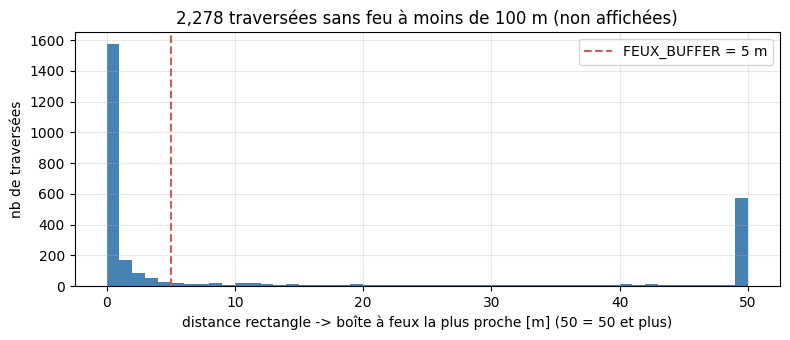

  GE_traversees: 5,206 -> ../../Data/output/walk/comparison_GG_vs_GE/traversees/GE_traversees_rectangles.gpkg


In [5]:
pyogrio.set_gdal_config_options({"SHAPE_RESTORE_SHX": "YES"})   # tolère un .shx manquant
feux = read_vector(FEUX_PATH)
if feux.crs is None:
    print(f"  Attention : boîtes à feux sans CRS, {operation_crs} supposé")
    feux = feux.set_crs(operation_crs)
feux = feux.to_crs(operation_crs)
feux = feux[feux.geometry.notna() & ~feux.geometry.is_empty].reset_index(drop=True)
if FEUX_COLUMN is not None:
    feux = feux[feux[FEUX_COLUMN].astype(str).isin([str(v) for v in FEUX_VALUES])].reset_index(drop=True)
print(f"Boîtes à feux : {len(feux):,} | colonnes : {[c for c in feux.columns if c != 'geometry']}")

near = gpd.sjoin_nearest(gt[["geometry"]], feux[["geometry"]], how="left",
                         max_distance=100, distance_col="d_feu")
gt["d_feu"] = near.groupby(level=0)["d_feu"].min().reindex(gt.index)       # NaN = rien à moins de 100 m
ft = shapely.STRtree(feux.geometry.values)
gi, _ = ft.query(gt.geometry.values, predicate="dwithin", distance=FEUX_BUFFER)
gt["n_feux"] = np.bincount(gi, minlength=len(gt))
gt["avec_feux"] = gt["n_feux"] > 0
gt["classe"] = np.where(gt["avec_feux"], "avec_feux", "sans_feux")
print(gt["classe"].value_counts().to_string())

# Distribution des distances : permet de choisir FEUX_BUFFER (on attend deux bosses bien séparées)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(gt["d_feu"].dropna().clip(upper=50), bins=np.arange(0, 51, 1), color="steelblue")
ax.axvline(FEUX_BUFFER, color="indianred", ls="--", label=f"FEUX_BUFFER = {FEUX_BUFFER:g} m")
ax.set(xlabel="distance rectangle -> boîte à feux la plus proche [m] (50 = 50 et plus)",
       ylabel="nb de traversées", title=f"{gt['d_feu'].isna().sum():,} traversées sans feu à moins de 100 m (non affichées)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

save_gpkg(gt, os.path.join(output_dir, "GE_traversees_rectangles.gpkg"), "GE_traversees")

## 3. Nœuds OSM : chargement, zone couverte, répartition

La couche OTC ne couvre pas tout le canton : certains secteurs (probablement des routes communales) n'ont **aucun** marquage, toutes catégories confondues. Un nœud OSM dans ces secteurs serait compté faux positif à tort. Avec `USE_COVERAGE_MASK`, on n'évalue que les nœuds à moins de `COVERAGE_BUFFER` m d'un marquage OTC quelconque.

OSM : 17,168 nœuds crossing
  dans le canton : 6,807


/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/venv/lib/python3.11/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiLineString' is converted to 'MultiLineString Z'
  return ogr_read(


  dans la zone couverte par l'OTC : 6,573


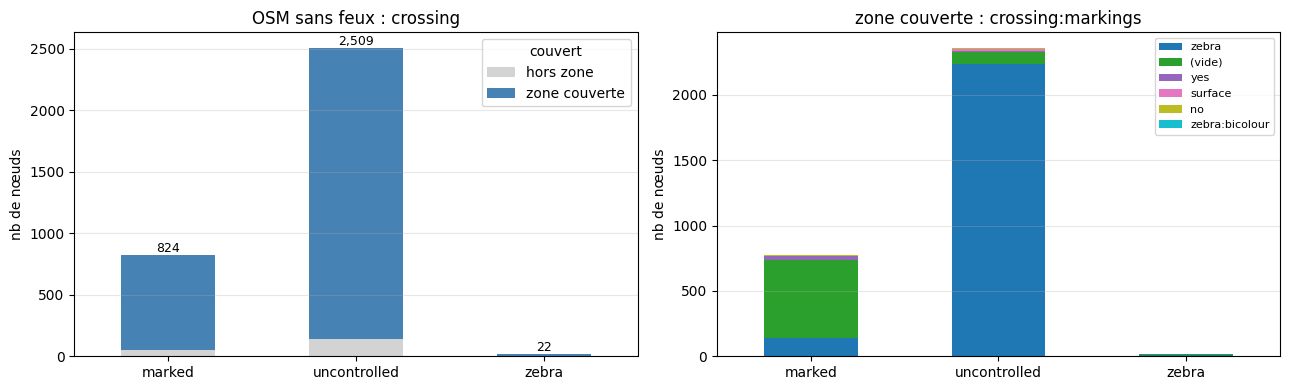

couvert,hors zone,zone couverte
crossing_val,,
marked,53,771
uncontrolled,144,2365
zebra,3,19


In [6]:
osm = read_vector(OSM_PATH).to_crs(operation_crs)
osm = osm[osm.geom_type == "Point"].reset_index(drop=True)
print(f"OSM : {len(osm):,} nœuds crossing")

if CLIP_TO_DOMAIN:
    if os.path.exists(domain_path):
        domain = load_domain(domain_path)
        osm = osm[osm.within(domain)].reset_index(drop=True)
        print(f"  dans le canton : {len(osm):,}")
    else:
        print(f"  Attention : {domain_path} introuvable, pas de découpe au canton")

if USE_COVERAGE_MASK:
    allm = pyogrio.read_dataframe(MARQUAGE_PATH, layer=MARQUAGE_LAYER, columns=[]).to_crs(operation_crs)
    mt = shapely.STRtree(shapely.force_2d(allm.geometry.values))
    pi, _ = mt.query(osm.geometry.values, predicate="dwithin", distance=COVERAGE_BUFFER)
    osm["couvert"] = np.isin(np.arange(len(osm)), pi)
    del allm, mt
else:
    osm["couvert"] = True
print(f"  dans la zone couverte par l'OTC : {osm['couvert'].sum():,}")

osm["crossing_val"] = osm[OSM_COLUMN].fillna("").astype(str).str.strip()
osm["classe_osm"] = np.select([osm["crossing_val"].isin(OSM_AVEC_FEUX_VALUES),
                               osm["crossing_val"].isin(OSM_SANS_FEUX_VALUES)],
                              ["avec_feux", "sans_feux"], "autre")
lab = lambda v: v if v else "(vide)"

# --- Histogramme des catégories "sans feux" ------------------------------
sf = osm[osm["classe_osm"] == "sans_feux"]
mk_col = "crossing:markings" if "crossing:markings" in osm.columns else None
fig, axes = plt.subplots(1, 2 if mk_col else 1, figsize=(13 if mk_col else 7, 4), squeeze=False)
tab = pd.crosstab(sf["crossing_val"].map(lab), sf["couvert"].map({True: "zone couverte", False: "hors zone"}))
tab = tab.reindex([lab(v) for v in OSM_SANS_FEUX_VALUES]).fillna(0)
tab.plot.bar(stacked=True, ax=axes[0, 0], color={"zone couverte": "steelblue", "hors zone": "lightgrey"}, rot=0)
for k, tot in enumerate(tab.sum(axis=1)):
    axes[0, 0].text(k, tot, f"{int(tot):,}", ha="center", va="bottom", fontsize=9)
axes[0, 0].set(title="OSM sans feux : crossing", xlabel="", ylabel="nb de nœuds")
if mk_col:
    sfc = sf[sf["couvert"]]
    tab2 = pd.crosstab(sfc["crossing_val"].map(lab), sfc[mk_col].fillna("(vide)"))
    tab2 = tab2[tab2.sum().sort_values(ascending=False).index[:6]]
    tab2.plot.bar(stacked=True, ax=axes[0, 1], rot=0, colormap="tab10")
    axes[0, 1].set(title=f"zone couverte : {mk_col}", xlabel="", ylabel="nb de nœuds")
    axes[0, 1].legend(fontsize=8)
for a in axes.flat:
    a.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()
display(tab.astype(int))

### 3 bis. Proportions des valeurs d'un tag OSM : urbain vs non urbain (tout le Grand Genève)

Tous les nœuds de `OSM_PATH` sont utilisés, **sans découpe au canton ni masque de couverture OTC**. Chaque nœud est classé *urbain* s'il tombe dans la tâche urbaine du Grand Genève, *non urbain* sinon. `TACHE_URBAINE_BUFFER` élargit la tâche urbaine de quelques mètres, par exemple pour rattacher les nœuds posés sur une route en bordure de la zone bâtie. Les proportions sont calculées **dans chaque zone** (les barres d'une même couleur somment à 100 %). Changer `TAG` pour analyser un autre tag, ou appeler `plot_tag_proportions(osm_gg, "autre_tag")`.

/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/venv/lib/python3.11/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


OSM Grand Genève : 17,168 nœuds | buffer tâche urbaine = 100 m | urbain : 17,040 | non urbain : 128


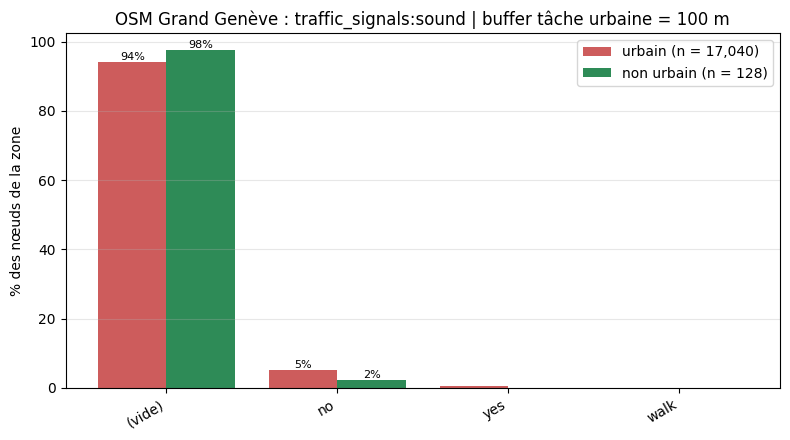

n                        %                 
zone   urbain non urbain  total urbain non urbain total
val                                                    
(vide)  16045        125  16170   94.2       97.7  94.2
no        881          3    884    5.2        2.3   5.1
yes       113          0    113    0.7        0.0   0.7
walk        1          0      1    0.0        0.0   0.0

In [30]:
###----change here-----
TAG = "traffic_signals:sound"                          # tag OSM à analyser (n'importe quelle colonne de OSM_PATH, ex. "crossing:markings")
TOP_N = 10                                # nb max de valeurs affichées, les autres sont regroupées dans "(autres)"
INCLURE_VIDE = True                       # False : ignorer les nœuds sans valeur pour ce tag

TACHE_URBAINE_PATH = f"{input_file_path}/network_agreg/AGGLO_TACHE_URBAINE_2022.gpkg"   # à adapter
TACHE_URBAINE_LAYER = None                # None = seule couche du fichier
TACHE_URBAINE_BUFFER = 100              # [m] buffer autour de la tâche urbaine (0 = pas de buffer)
###--------------------

# --- Nœuds OSM sur tout le Grand Genève (pas de découpe au canton) ------
osm_gg = read_vector(OSM_PATH).to_crs(operation_crs)
osm_gg = osm_gg[osm_gg.geom_type == "Point"].reset_index(drop=True)

# --- Tâche urbaine : urbain / non urbain ---------------------------------
tu = read_vector(TACHE_URBAINE_PATH, layer=TACHE_URBAINE_LAYER)
if tu.crs is None:
    print(f"  Attention : tâche urbaine sans CRS, {operation_crs} supposé")
    tu = tu.set_crs(operation_crs)
tu = tu.to_crs(operation_crs)
tu_geoms = np.array([clean_any_geom(g) for g in tu.geometry.values], dtype=object)
tu_geoms = shapely.get_parts(tu_geoms[[g is not None for g in tu_geoms]])
tu_geoms = tu_geoms[shapely.get_type_id(tu_geoms) == 3]          # polygones seulement
if TACHE_URBAINE_BUFFER > 0:
    tu_geoms = shapely.buffer(tu_geoms, TACHE_URBAINE_BUFFER)
pi, _ = shapely.STRtree(tu_geoms).query(osm_gg.geometry.values, predicate="intersects")
osm_gg["zone"] = np.where(np.isin(np.arange(len(osm_gg)), pi), "urbain", "non urbain")
print(f"OSM Grand Genève : {len(osm_gg):,} nœuds | buffer tâche urbaine = {TACHE_URBAINE_BUFFER:g} m | "
      + " | ".join(f"{z} : {n:,}" for z, n in osm_gg["zone"].value_counts().items()))


def plot_tag_proportions(gdf, tag, top_n=TOP_N, inclure_vide=INCLURE_VIDE):
    """Proportion des valeurs de `tag`, calculée séparément dans la zone urbaine et non urbaine."""
    if tag not in gdf.columns:
        tags = sorted(c for c in gdf.columns if c not in ("geometry", "zone"))
        raise KeyError(f"tag {tag!r} absent. Colonnes disponibles : {tags}")
    val = gdf[tag].fillna("").astype(str).str.strip().replace("", "(vide)")
    d = pd.DataFrame({"val": val, "zone": gdf["zone"]})
    if not inclure_vide:
        d = d[d["val"] != "(vide)"]
    ordre = d["val"].value_counts().index
    if len(ordre) > top_n:
        d.loc[~d["val"].isin(ordre[:top_n]), "val"] = "(autres)"
        ordre = list(ordre[:top_n]) + ["(autres)"]

    zones = ["urbain", "non urbain"]
    n = pd.crosstab(d["val"], d["zone"]).reindex(index=ordre, columns=zones).fillna(0).astype(int)
    p = 100 * n / n.sum().replace(0, np.nan)
    n_tot = n.sum()

    fig, ax = plt.subplots(figsize=(max(8, 0.9 * len(ordre) + 3), 4.5))
    x, w = np.arange(len(ordre)), 0.4
    couleurs = {"urbain": "indianred", "non urbain": "seagreen"}
    for k, z in enumerate(zones):
        b = ax.bar(x + (k - 0.5) * w, p[z].fillna(0), w, color=couleurs[z],
                   label=f"{z} (n = {n_tot[z]:,})")
        ax.bar_label(b, labels=[f"{v:.0f}%" if v >= 1 else "" for v in p[z].fillna(0)], fontsize=8)
    ax.set_xticks(x, ordre, rotation=30, ha="right")
    ax.set(ylabel="% des nœuds de la zone", xlabel="",
           title=f"OSM Grand Genève : {tag} | buffer tâche urbaine = {TACHE_URBAINE_BUFFER:g} m"
                 + ("" if inclure_vide else " (vides exclus)"))
    ax.grid(axis="y", alpha=0.3); ax.legend(); plt.tight_layout()
    fig.savefig(os.path.join(output_dir, f"proportions_{tag.replace(':', '_')}_urbain_vs_non_urbain_buffer{TACHE_URBAINE_BUFFER:g}m.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

    n = n.assign(total=n.sum(axis=1))
    tab = pd.concat({"n": n, "%": (100 * n / n.sum()).round(1)}, axis=1)
    display(tab)
    return tab


tab_tag = plot_tag_proportions(osm_gg, TAG)

## 4. Fonction d'évaluation par rectangles

- Chaque nœud OSM est rattaché au rectangle **le plus proche, toutes classes confondues**, dans un rayon `radius` (0 si dedans).
- `TP` : rattaché à un rectangle de la classe évaluée. `FP_mauvaise_classe` : rattaché à un rectangle de l'autre classe (ex. OSM dit sans feux, l'OTC a des feux). `FP_hors_marquage` : aucun rectangle dans le rayon. `FP_doublon` : seulement si `ONE_TO_ONE`.
- **Précision** = TP / nœuds OSM (unité : nœuds). **Rappel** = rectangles de la classe avec au moins un TP / rectangles de la classe (unité : rectangles).

In [8]:
def eval_rectangles(pts, rects, target, radius, one_to_one=False):
    pts = pts[["geometry"] + [c for c in ["crossing_val"] if c in pts.columns]].copy()
    j = gpd.sjoin_nearest(pts[["geometry"]], rects[["geometry", "gt_id", "classe"]], how="left",
                          max_distance=max(radius, 1e-9), distance_col="dist")
    j = j.sort_values("dist", kind="stable")
    j = j[~j.index.duplicated()].reindex(pts.index)            # égalités : un seul rectangle
    pts["gt_id"], pts["dist"], pts["classe_gt"] = j["gt_id"], j["dist"], j["classe"]
    pts["statut"] = np.select([pts["gt_id"].isna(), pts["classe_gt"] != target],
                              ["FP_hors_marquage", "FP_mauvaise_classe"], "TP")
    if one_to_one:
        tp = pts[pts["statut"] == "TP"].sort_values("dist", kind="stable")
        pts.loc[tp.index[tp.duplicated("gt_id")], "statut"] = "FP_doublon"
    cible = rects[rects["classe"] == target]
    found = set(pts.loc[pts["statut"] == "TP", "gt_id"].astype(int))
    fn = cible[~cible["gt_id"].isin(found)]
    n_tp = int((pts["statut"] == "TP").sum())
    per_rect = pts.loc[pts["statut"] == "TP", "gt_id"].value_counts()
    m = {"n_osm": len(pts), "TP": n_tp,
         "FP_hors_marquage": int((pts["statut"] == "FP_hors_marquage").sum()),
         "FP_mauvaise_classe": int((pts["statut"] == "FP_mauvaise_classe").sum()),
         "FP_doublon": int((pts["statut"] == "FP_doublon").sum()),
         "n_rect": len(cible), "rect_trouves": len(found), "FN": len(fn),
         "rect_plusieurs_noeuds": int((per_rect > 1).sum()),
         **_prf(n_tp / len(pts) if len(pts) else 0.0, len(found) / len(cible) if len(cible) else 0.0)}
    return m, pts, fn


def show_eval(name, target, pts, radius):
    m, res, fn = eval_rectangles(pts, gt, target, radius, ONE_TO_ONE)
    print(f"[{name} | rayon = {radius:g} m | one_to_one = {ONE_TO_ONE}]")
    for k, v in m.items():
        print(f"  {k:>22}: {v:,.3f}" if isinstance(v, float) else f"  {k:>22}: {v:,}")
    if "crossing_val" in res.columns:
        display(pd.crosstab(res["crossing_val"].map(lab), res["statut"], margins=True))
    tag = f"{radius:g}m"
    save_gpkg(res[res["statut"] == "TP"], os.path.join(output_dir, f"{name}_TP_r{tag}.gpkg"), f"TP_{name}")
    save_gpkg(res[res["statut"] != "TP"], os.path.join(output_dir, f"{name}_FP_r{tag}.gpkg"), f"FP_{name}")
    save_gpkg(fn, os.path.join(output_dir, f"{name}_FN_r{tag}.gpkg"), f"FN_{name}")
    return m, res, fn


def sweep_plot(name, target, pts):
    rows = [{"radius_m": float(r), **eval_rectangles(pts, gt, target, float(r), ONE_TO_ONE)[0]}
            for r in RADIUS_RANGE]
    sw = pd.DataFrame(rows)
    sw.to_csv(os.path.join(output_dir, f"{name}_metrics_vs_radius.csv"), index=False)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(sw.radius_m, sw.precision, "o-", ms=3, label="précision (nœuds OSM)")
    ax.plot(sw.radius_m, sw.recall, "s-", ms=3, label="rappel (rectangles GE)")
    ax.plot(sw.radius_m, sw.F1, "^-", ms=3, label="F1")
    ax.axvline(ASSIGN_RADIUS, color="grey", ls="--", lw=1, label=f"ASSIGN_RADIUS = {ASSIGN_RADIUS:g} m")
    ax.set(xlabel="rayon de rattachement [m]", ylabel="score", ylim=(0, 1.05), title=name)
    ax.grid(alpha=0.3); ax.legend(); plt.tight_layout()
    fig.savefig(os.path.join(output_dir, f"{name}_metrics_vs_radius.png"), dpi=150, bbox_inches="tight")
    plt.show()
    return sw

## 5. Traversées sans feux

In [9]:
osm_sf = osm[(osm["classe_osm"] == "sans_feux") & osm["couvert"]].reset_index(drop=True)
m_sf, res_sf, fn_sf = show_eval("sans_feux", "sans_feux", osm_sf, ASSIGN_RADIUS)

[sans_feux | rayon = 5 m | one_to_one = False]
                   n_osm: 3,155
                      TP: 2,570
        FP_hors_marquage: 333
      FP_mauvaise_classe: 252
              FP_doublon: 0
                  n_rect: 3,291
            rect_trouves: 2,523
                      FN: 768
   rect_plusieurs_noeuds: 41
               precision: 0.815
                  recall: 0.767
                      F1: 0.790


statut,FP_hors_marquage,FP_mauvaise_classe,TP,All
crossing_val,,,,
marked,63,63,645,771
uncontrolled,261,189,1915,2365
zebra,9,0,10,19
All,333,252,2570,3155


  TP_sans_feux: 2,570 -> ../../Data/output/walk/comparison_GG_vs_GE/traversees/sans_feux_TP_r5m.gpkg
  FP_sans_feux: 585 -> ../../Data/output/walk/comparison_GG_vs_GE/traversees/sans_feux_FP_r5m.gpkg
  FN_sans_feux: 768 -> ../../Data/output/walk/comparison_GG_vs_GE/traversees/sans_feux_FN_r5m.gpkg


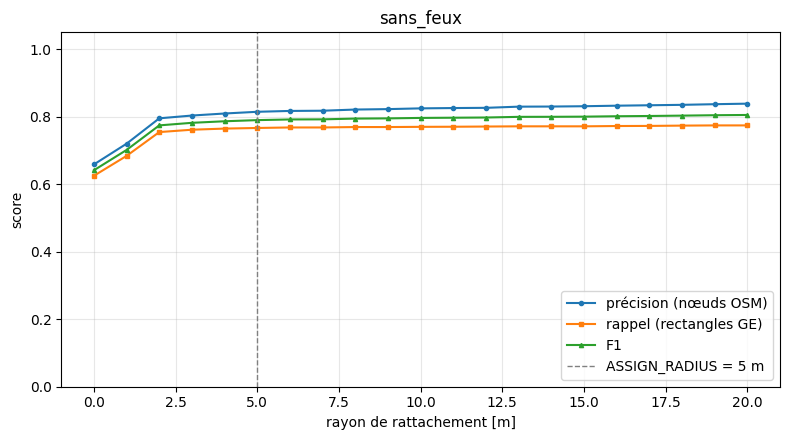

,radius_m,n_osm,TP,FP_hors_marquage,FP_mauvaise_classe,FP_doublon,n_rect,rect_trouves,FN,rect_plusieurs_noeuds,precision,recall,F1
0,0.0,3155,2078,911,166,0,3291,2057,1234,16,0.659,0.625,0.641
1,1.0,3155,2272,682,201,0,3291,2251,1040,16,0.720,0.684,0.702
2,2.0,3155,2509,407,239,0,3291,2483,808,21,0.795,0.754,0.774
3,3.0,3155,2535,378,242,0,3291,2506,785,24,0.803,0.761,0.782
4,4.0,3155,2554,353,248,0,3291,2517,774,32,0.810,0.765,0.787
5,5.0,3155,2570,333,252,0,3291,2523,768,41,0.815,0.767,0.790
6,6.0,3155,2578,325,252,0,3291,2528,763,44,0.817,0.768,0.792
7,7.0,3155,2580,323,252,0,3291,2528,763,45,0.818,0.768,0.792
8,8.0,3155,2591,311,253,0,3291,2532,759,50,0.821,0.769,0.794
9,9.0,3155,2595,307,253,0,3291,2532,759,54,0.823,0.769,0.795


In [10]:
sweep_sf = sweep_plot("sans_feux", "sans_feux", osm_sf)
display(sweep_sf.round(3))

## 6. Contrôle croisé : toutes les valeurs OSM vs classe GE

Pour chaque valeur de `crossing` (zone couverte), dans quelle classe de rectangle tombent les nœuds ? Utile pour voir les `uncontrolled` qui ont en réalité des feux, ou les `unmarked` posés sur un marquage.

In [11]:
_, res_all, _ = eval_rectangles(osm[osm["couvert"]].reset_index(drop=True), gt, "sans_feux", ASSIGN_RADIUS)
res_all["classe_gt"] = res_all["classe_gt"].fillna("aucun rectangle")
conf = pd.crosstab(res_all["crossing_val"].map(lab), res_all["classe_gt"], margins=True)
display(conf)
display((100 * pd.crosstab(res_all["crossing_val"].map(lab), res_all["classe_gt"], normalize="index")).round(1))

classe_gt,aucun rectangle,avec_feux,sans_feux,All
crossing_val,,,,
(vide),55,15,40,110
informal,6,0,0,6
marked,63,63,645,771
pavement,2,0,0,2
traffic_signals,32,1462,24,1518
uncontrolled,261,189,1915,2365
unmarked,1673,21,88,1782
zebra,9,0,10,19
All,2101,1750,2722,6573


classe_gt,aucun rectangle,avec_feux,sans_feux
crossing_val,,,
(vide),50.0,13.6,36.4
informal,100.0,0.0,0.0
marked,8.2,8.2,83.7
pavement,100.0,0.0,0.0
traffic_signals,2.1,96.3,1.6
uncontrolled,11.0,8.0,81.0
unmarked,93.9,1.2,4.9
zebra,47.4,0.0,52.6


## 7. Traversées avec feux

### 7a. Même règle que pour les sans feux (rectangles avec feux vs `crossing = traffic_signals`)

In [12]:
osm_af = osm[(osm["classe_osm"] == "avec_feux") & osm["couvert"]].reset_index(drop=True)
m_af, res_af, fn_af = show_eval("avec_feux", "avec_feux", osm_af, ASSIGN_RADIUS)

[avec_feux | rayon = 5 m | one_to_one = False]
                   n_osm: 1,518
                      TP: 1,462
        FP_hors_marquage: 32
      FP_mauvaise_classe: 24
              FP_doublon: 0
                  n_rect: 1,915
            rect_trouves: 1,400
                      FN: 515
   rect_plusieurs_noeuds: 56
               precision: 0.963
                  recall: 0.731
                      F1: 0.831


statut,FP_hors_marquage,FP_mauvaise_classe,TP,All
crossing_val,,,,
traffic_signals,32,24,1462,1518
All,32,24,1462,1518


  TP_avec_feux: 1,462 -> ../../Data/output/walk/comparison_GG_vs_GE/traversees/avec_feux_TP_r5m.gpkg
  FP_avec_feux: 56 -> ../../Data/output/walk/comparison_GG_vs_GE/traversees/avec_feux_FP_r5m.gpkg
  FN_avec_feux: 515 -> ../../Data/output/walk/comparison_GG_vs_GE/traversees/avec_feux_FN_r5m.gpkg


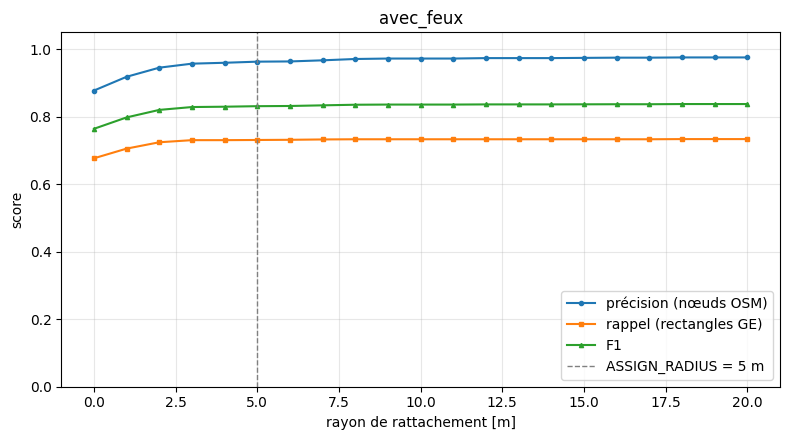

,radius_m,n_osm,TP,FP_hors_marquage,FP_mauvaise_classe,FP_doublon,n_rect,rect_trouves,FN,rect_plusieurs_noeuds,precision,recall,F1
0,0.0,1518,1332,165,21,0,1915,1296,619,36,0.877,0.677,0.764
1,1.0,1518,1394,101,23,0,1915,1351,564,41,0.918,0.705,0.798
2,2.0,1518,1435,59,24,0,1915,1387,528,46,0.945,0.724,0.820
3,3.0,1518,1453,41,24,0,1915,1399,516,52,0.957,0.731,0.829
4,4.0,1518,1457,37,24,0,1915,1399,516,54,0.960,0.731,0.830
5,5.0,1518,1462,32,24,0,1915,1400,515,56,0.963,0.731,0.831
6,6.0,1518,1463,31,24,0,1915,1401,514,56,0.964,0.732,0.832
7,7.0,1518,1468,25,25,0,1915,1403,512,58,0.967,0.733,0.834
8,8.0,1518,1474,18,26,0,1915,1404,511,61,0.971,0.733,0.835
9,9.0,1518,1476,15,27,0,1915,1404,511,63,0.972,0.733,0.836


In [13]:
sweep_af = sweep_plot("avec_feux", "avec_feux", osm_af)
display(sweep_af.round(3))

### 7b. Reprise de la comparaison de 2_1 : boîtes à feux (fusionnées) vs nœuds `traffic_signals`

⚠️ Les boîtes à feux incluent les feux pour véhicules (carrefours sans traversée, etc.) : le rappel est structurellement bas. La comparaison 7a est plus pertinente ; celle-ci est gardée pour continuité avec 2_1.

fusion (r = 15 m) : boîtes à feux 11,726 -> 2,025 | OSM 1,518 -> 924
[feux points | buffer = 10 m]
          TP: 785
          FN: 1,240
          FP: 139
   precision: 0.850
      recall: 0.388
          F1: 0.532
  FN_feux: 1,240 -> ../../Data/output/walk/comparison_GG_vs_GE/traversees/feux_points_FN_buffer10m_fusion15m.gpkg
  FP_feux: 139 -> ../../Data/output/walk/comparison_GG_vs_GE/traversees/feux_points_FP_buffer10m_fusion15m.gpkg


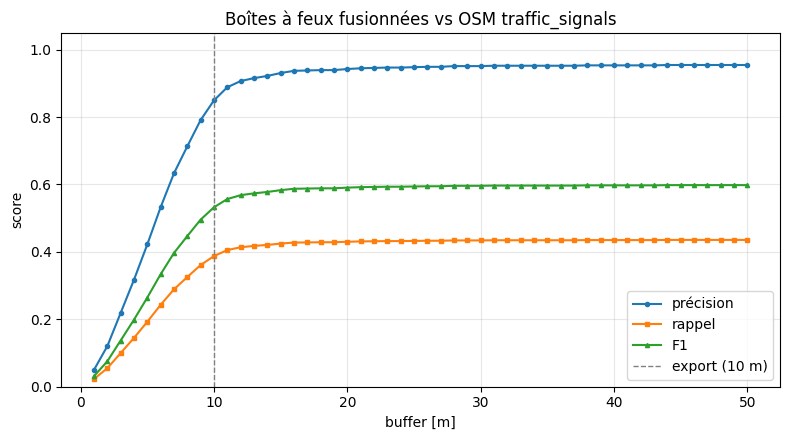

In [14]:
p_gt = feux[["geometry"]].copy()
p_test = osm_af[["geometry", "crossing_val"]].copy()
p_ftag = ""
if FUSION:
    n_gt, n_test = len(p_gt), len(p_test)
    p_gt = fusion_points(p_gt, FUSION_RADIUS)
    p_test = fusion_points(p_test, FUSION_RADIUS, keep_cols=["crossing_val"])
    p_ftag = f"_fusion{FUSION_RADIUS:g}m"
    print(f"fusion (r = {FUSION_RADIUS:g} m) : boîtes à feux {n_gt:,} -> {len(p_gt):,} | OSM {n_test:,} -> {len(p_test):,}")

p_metrics, p_fn, p_fp = point_metrics(p_gt, p_test, POINT_BUFFER_EXPORT)
print(f"[feux points | buffer = {POINT_BUFFER_EXPORT:g} m]")
for k, v in p_metrics.items():
    print(f"  {k:>10}: {v:,.3f}" if isinstance(v, float) else f"  {k:>10}: {v:,}")
save_gpkg(p_fn, os.path.join(output_dir, f"feux_points_FN_buffer{POINT_BUFFER_EXPORT:g}m{p_ftag}.gpkg"), "FN_feux")
save_gpkg(p_fp, os.path.join(output_dir, f"feux_points_FP_buffer{POINT_BUFFER_EXPORT:g}m{p_ftag}.gpkg"), "FP_feux")

p_sweep = pd.DataFrame([{"buffer_m": float(b), **point_metrics(p_gt, p_test, float(b))[0]}
                        for b in POINT_BUFFER_RANGE])
p_sweep.to_csv(os.path.join(output_dir, f"feux_points_metrics_vs_buffer{p_ftag}.csv"), index=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(p_sweep.buffer_m, p_sweep.precision, "o-", ms=3, label="précision")
ax.plot(p_sweep.buffer_m, p_sweep.recall, "s-", ms=3, label="rappel")
ax.plot(p_sweep.buffer_m, p_sweep.F1, "^-", ms=3, label="F1")
ax.axvline(POINT_BUFFER_EXPORT, color="grey", ls="--", lw=1, label=f"export ({POINT_BUFFER_EXPORT:g} m)")
ax.set(xlabel="buffer [m]", ylabel="score", ylim=(0, 1.05),
       title=f"Boîtes à feux{' fusionnées' if FUSION else ''} vs OSM traffic_signals")
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

## 8. Récapitulatif

In [15]:
recap = pd.DataFrame({"sans_feux (rectangles)": m_sf, "avec_feux (rectangles)": m_af,
                      "avec_feux (points 2_1)": p_metrics}).T
display(recap)
recap.to_csv(os.path.join(output_dir, "recap_traversees.csv"))

,n_osm,TP,FP_hors_marquage,FP_mauvaise_classe,FP_doublon,n_rect,rect_trouves,FN,rect_plusieurs_noeuds,precision,recall,F1,FP
sans_feux (rectangles),3155.0,2570.0,333.0,252.0,0.0,3291.0,2523.0,768.0,41.0,0.814580,0.766636,0.789881,NaN
avec_feux (rectangles),1518.0,1462.0,32.0,24.0,0.0,1915.0,1400.0,515.0,56.0,0.963109,0.731070,0.831200,NaN
avec_feux (points 2_1),NaN,785.0,NaN,NaN,NaN,NaN,NaN,1240.0,NaN,0.849567,0.387654,0.532384,139.0
